# 01 — EDA: Amazon Reviews 2023, Musical Instruments

Figures and numbers for the report. Inputs come from `make prepare` (`data/processed/*.parquet`, `results/data/dataset_stats.json`). Figures are saved to `results/figures/`. Re-run with `make eda`.

In [1]:
import json

import matplotlib.pyplot as plt
import polars as pl

from recsys.config import PROJECT_ROOT, load_config
from recsys.data.preprocess import build_interactions

cfg = load_config().resolve(PROJECT_ROOT)
PROCESSED = cfg.data.processed_dir
FIG_DIR = cfg.results_dir / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

train, val, test, items = (pl.read_parquet(PROCESSED / f'{n}.parquet') for n in ('train', 'val', 'test', 'items'))
history = pl.concat([train, val])
stats = json.loads((cfg.results_dir / 'data/dataset_stats.json').read_text())
# full interaction history incl. the dropped post-test tail, for the timeline only
all_interactions = build_interactions(
    pl.read_parquet(cfg.data.interim_dir / 'reviews.parquet'))

In [2]:
# Reference palette (dataviz skill, light mode): one hue per single-series chart,
# recessive ink and grid.
SERIES = '#2a78d6'
VAL_BAND, TEST_BAND = '#eb6834', '#1baf7a'
MUTED = '#a3a29c'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'savefig.facecolor': '#fcfcfb', 'axes.edgecolor': '#d6d5cf',
    'axes.labelcolor': '#52514e', 'text.color': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True,
    'grid.color': '#ebeae6', 'grid.linewidth': 0.8, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'font.size': 10, 'figure.dpi': 110,
    'axes.axisbelow': True,  # grid behind data
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150)
    plt.show()

## Dataset at a glance

In [3]:
s = stats['interactions']
pl.DataFrame({
    'metric': ['raw reviews', 'unique user-item interactions', 'users', 'items',
               'density', 'interactions / user (mean)', 'users with 1 interaction',
               'users with 5+ interactions', 'interactions on top-20% items',
               'dropped after test_end'],
    'value': [f"{stats['raw_reviews']:,}", f"{s['interactions']:,}", f"{s['users']:,}",
              f"{s['items']:,}", f"{s['density']:.2e}",
              f"{s['interactions_per_user_mean']:.2f}",
              f"{s['users_with_1_interaction_share']:.1%}",
              f"{s['users_with_5plus_interactions_share']:.1%}",
              f"{s['top_20pct_items_interaction_share']:.1%}",
              f"{stats['dropped_after_test_end']:,}"],
})

metric,value
str,str
"""raw reviews""","""3,017,439"""
"""unique user-item interactions""","""2,975,551"""
"""users""","""1,762,679"""
"""items""","""213,571"""
"""density""","""7.90e-06"""
"""interactions / user (mean)""","""1.69"""
"""users with 1 interaction""","""74.9%"""
"""users with 5+ interactions""","""4.7%"""
"""interactions on top-20% items""","""85.5%"""


## Activity over time and the split windows

Validation = Oct–Dec 2022, test = Jan–Mar 2023. After March 2023 the monthly volume collapses (data-collection tail), so those reviews are dropped.

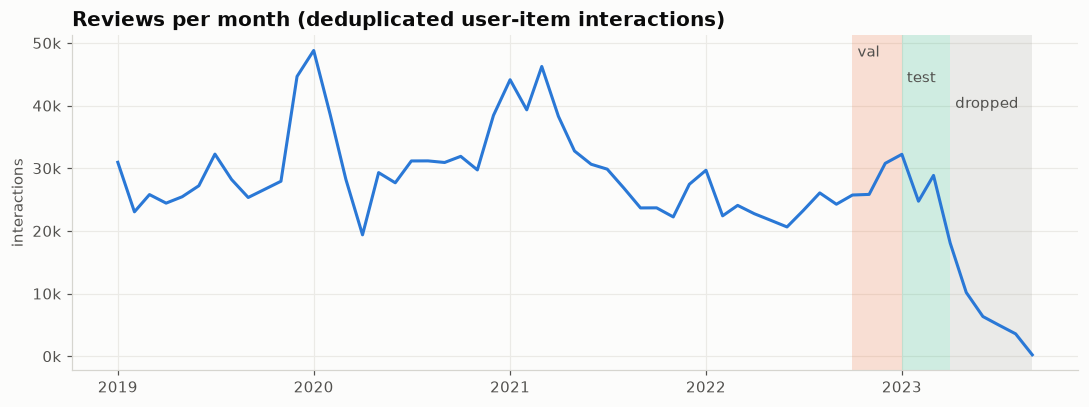

In [4]:
monthly = (all_interactions.filter(pl.col('timestamp') >= pl.datetime(2019, 1, 1))
           .group_by(pl.col('timestamp').dt.truncate('1mo').alias('month')).len()
           .sort('month'))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(monthly['month'], monthly['len'], color=SERIES, linewidth=2)
sp = cfg.split
top = ax.get_ylim()[1]
bands = [(sp.val_start, sp.test_start, VAL_BAND, 'val', 0.97),
         (sp.test_start, sp.test_end, TEST_BAND, 'test', 0.89),
         (sp.test_end, monthly['month'].max().date(), MUTED, 'dropped', 0.81)]
for lo, hi, color, label, y in bands:
    ax.axvspan(lo, hi, color=color, alpha=0.2, linewidth=0)
    ax.text(lo, top * y, f' {label}', va='top', color='#52514e')
ax.set_title('Reviews per month (deduplicated user-item interactions)')
ax.set_ylabel('interactions')
ax.yaxis.set_major_formatter(lambda v, _: f'{v / 1000:.0f}k')
save(fig, 'monthly_interactions')

## Sparsity: how many interactions does a user have?

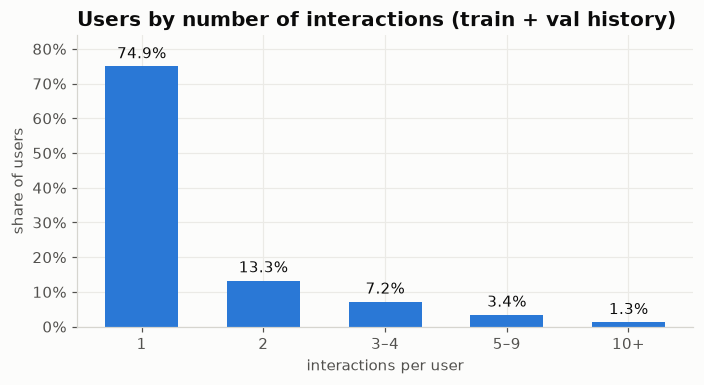

In [5]:
BUCKETS = [(1, 1, '1'), (2, 2, '2'), (3, 4, '3–4'), (5, 9, '5–9'), (10, None, '10+')]

def bucket_shares(counts: pl.Series, buckets) -> list[float]:
    n = counts.len()
    return [((counts >= lo) & ((counts <= hi) if hi is not None else True)).sum() / n
            for lo, hi, _ in buckets]

per_user = history.group_by('user_id').len()['len']
shares = bucket_shares(per_user, BUCKETS)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar([b[2] for b in BUCKETS], shares, color=SERIES, width=0.6)
ax.bar_label(bars, labels=[f'{v:.1%}' for v in shares], padding=3)
ax.margins(y=0.12)
ax.set_title('Users by number of interactions (train + val history)')
ax.set_xlabel('interactions per user')
ax.set_ylabel('share of users')
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
save(fig, 'user_activity')

## Long tail: how concentrated is item popularity?

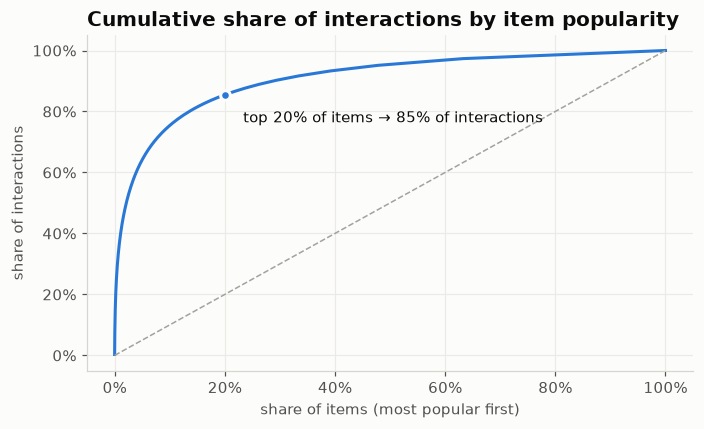

In [6]:
per_item = history.group_by('item_id').len()['len'].sort(descending=True)
item_share = (pl.Series(range(1, per_item.len() + 1)) / per_item.len()).to_numpy()
cum_share = (per_item.cum_sum() / per_item.sum()).to_numpy()
head = int(per_item.len() * 0.2)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(item_share, cum_share, color=SERIES, linewidth=2)
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle='--')
ax.scatter([item_share[head - 1]], [cum_share[head - 1]], s=40, color=SERIES,
           zorder=3, edgecolor='#fcfcfb', linewidth=2)
ax.annotate(f'top 20% of items → {cum_share[head - 1]:.0%} of interactions',
            (item_share[head - 1], cum_share[head - 1]), xytext=(12, -18),
            textcoords='offset points')
ax.set_title('Cumulative share of interactions by item popularity')
ax.set_xlabel('share of items (most popular first)')
ax.set_ylabel('share of interactions')
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(lambda v, _: f'{v:.0%}')
save(fig, 'item_long_tail')

## What do people review? Top-level categories

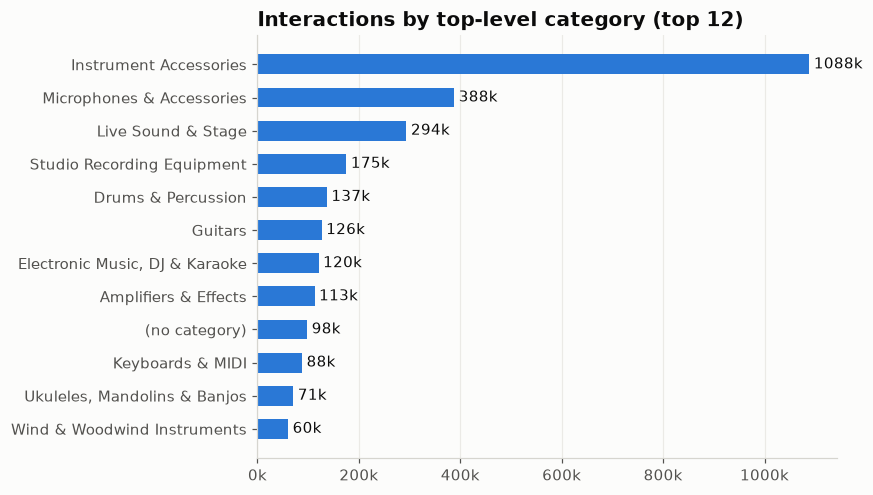

In [7]:
by_cat = (history.join(items.select('item_id', 'top_category'), on='item_id', how='left')
          .with_columns(pl.col('top_category').fill_null('(no category)'))
          .group_by('top_category').len().sort('len', descending=True).head(12)
          .sort('len'))
fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.barh(by_cat['top_category'], by_cat['len'], color=SERIES, height=0.6)
ax.bar_label(bars, labels=[f'{v / 1000:.0f}k' for v in by_cat['len']], padding=3)
ax.set_title('Interactions by top-level category (top 12)')
ax.xaxis.set_major_formatter(lambda v, _: f'{v / 1000:.0f}k')
ax.grid(axis='y', visible=False)
save(fig, 'top_categories')

## Cold start in the test window

History = train + val. Users with no history can only get non-personalized recommendations (popular / trending).

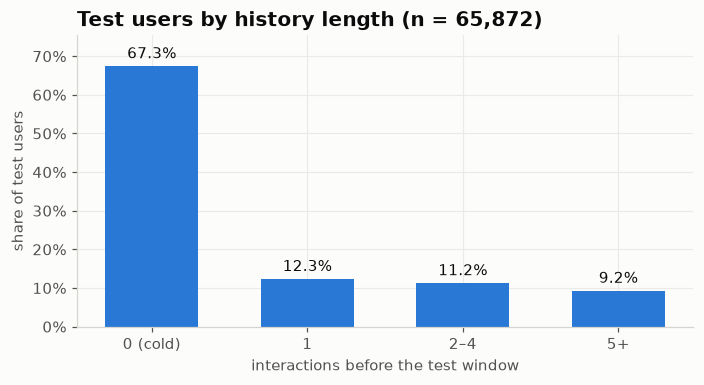

test interactions on items unseen in history: 12.5%


In [8]:
HIST_BUCKETS = [(0, 0, '0 (cold)'), (1, 1, '1'), (2, 4, '2–4'), (5, None, '5+')]
test_hist = (test.select('user_id').unique()
             .join(history.group_by('user_id').len(), on='user_id', how='left')
             .fill_null(0)['len'])
shares = bucket_shares(test_hist, HIST_BUCKETS)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar([b[2] for b in HIST_BUCKETS], shares, color=SERIES, width=0.6)
ax.bar_label(bars, labels=[f'{v:.1%}' for v in shares], padding=3)
ax.margins(y=0.12)
ax.set_title(f'Test users by history length (n = {test_hist.len():,})')
ax.set_xlabel('interactions before the test window')
ax.set_ylabel('share of test users')
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
save(fig, 'test_user_history')
unseen = stats['splits']['test']['interactions_on_unseen_items_share']
print(f'test interactions on items unseen in history: {unseen:.1%}')

## Ratings

Reviews are treated as implicit positive feedback; the skew below is why.

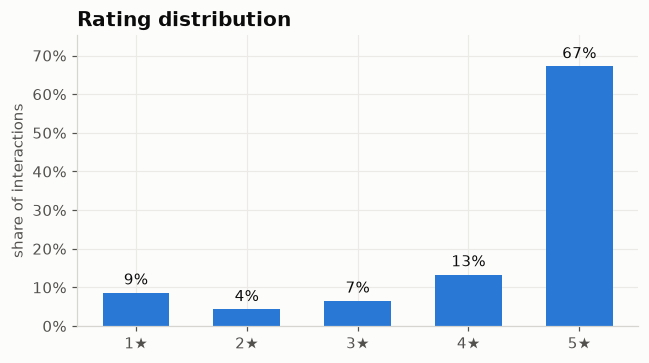

In [9]:
ratings = history.group_by('rating').len().sort('rating')
shares = (ratings['len'] / ratings['len'].sum()).to_list()
fig, ax = plt.subplots(figsize=(6, 3.4))
bars = ax.bar([f'{r:.0f}★' for r in ratings['rating']], shares, color=SERIES, width=0.6)
ax.bar_label(bars, labels=[f'{v:.0%}' for v in shares], padding=3)
ax.margins(y=0.12)
ax.set_title('Rating distribution')
ax.set_ylabel('share of interactions')
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
save(fig, 'ratings')

## Item feature coverage (inputs for content-based / category / brand models)

In [10]:
features = stats['item_features']
pl.DataFrame({
    'feature': [*features, 'distinct brands', 'distinct leaf categories'],
    'value': [*(f'{v:.1%}' for v in features.values()),
              f"{stats['distinct_brands']:,}", f"{stats['distinct_categories']:,}"],
})

feature,value
str,str
"""brand""","""98.3%"""
"""category""","""91.1%"""
"""price""","""39.7%"""
"""bought_together""","""0.0%"""
"""distinct brands""","""26,284"""
"""distinct leaf categories""","""566"""
